# EfficientNet-B3 + GRU + Attention Image Captioning (Flickr8k)

- Dataset: Flickr8k ([Flickr8k Dataset](https://www.kaggle.com/datasets/adityajn105/flickr8k) )

- Global feature extractor: EfficientNet-B3 (frozen, pre-extract feature bank)
- Region feature extractor: CNN feature-map top-k regions
- Region-context fusion: Multi-head attention
- Refinement: HAB-lite (channel + spatial)
- Decoder: GRU + attention
- Loss: Cross-Entropy
- Metric: BLEU


## Setup Config Imports


In [1]:
import os
import re
import gc
import copy
import json
import random
from pathlib import Path
from dataclasses import dataclass
from collections import Counter

import numpy as np
import nltk
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import efficientnet_b3, EfficientNet_B3_Weights

from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.tokenize import word_tokenize

@dataclass
class CFG:
    IMG_SIZE: int = 300
    MAX_LEN: int = 30
    MIN_FREQ: int = 2
    BATCH_SIZE: int = 128
    EPOCHS: int = 10
    LR: float = 3e-4
    MIN_LR: float = 1e-6
    WEIGHT_DECAY: float = 1e-2
    ADAM_BETA1: float = 0.9
    ADAM_BETA2: float = 0.999
    ADAM_EPS: float = 1e-8
    LABEL_SMOOTHING: float = 0.1
    WARMUP_EPOCHS: int = 2
    EMA_DECAY: float = 0.999
    USE_EMA: bool = True
    NUM_WORKERS: int = 2
    EXTRACT_BATCH_SIZE: int = 64
    EMBED_DIM: int = 256
    HIDDEN_DIM: int = 512
    FUSION_DIM: int = 512
    NUM_HEADS: int = 8
    DROPOUT: float = 0.2
    TOPK_REGIONS: int = 25
    CLIP_GRAD_NORM: float = 1.0
    EMPTY_CACHE_EVERY: int = 20
    PAD_TOKEN: str = '<pad>'
    SOS_TOKEN: str = '<sos>'
    EOS_TOKEN: str = '<eos>'
    UNK_TOKEN: str = '<unk>'


cfg = CFG()

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| GPUs:', torch.cuda.device_count())

nltk.download('punkt', quiet=True)


Device: cuda | GPUs: 2


True

## Dataset Prep


In [ ]:
DATA_ROOT = Path('/kaggle/input/datasets/adityajn105/flickr8k')
IMG_DIR = DATA_ROOT / 'Images'
CAP1 = DATA_ROOT / 'captions.txt'
CAP2 = DATA_ROOT / 'results.csv'

OUTPUT_DIR = Path('/kaggle/working/effb3_gru_flickr8k_output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_PATH = OUTPUT_DIR / 'best_model.pt'

if not IMG_DIR.exists():
    raise FileNotFoundError(f'Missing image dir: {IMG_DIR}')

ann_path = CAP1 if CAP1.exists() else CAP2
if ann_path is None or (not ann_path.exists()):
    raise FileNotFoundError(f'Missing caption file: {CAP1} or {CAP2}')

print('Path check:', IMG_DIR.exists(), ann_path)

records = []
if ann_path.name.lower().endswith('.txt'):
    import csv
    with ann_path.open('r', encoding='utf-8') as f:
        reader = csv.reader(f)
        header = next(reader, None)
        for row in reader:
            if len(row) < 2:
                continue
            image_name = row[0].strip()
            cap = row[1].strip()
            if not image_name or not cap:
                continue
            if '#' in image_name:
                image_name = image_name.split('#')[0]
            img_path = IMG_DIR / image_name
            if img_path.exists():
                img_id = image_name
                records.append((str(img_path), img_id, cap))
else:
    import csv
    with ann_path.open('r', encoding='utf-8') as f:
        reader = csv.DictReader(f, delimiter='|')
        for row in reader:
            image_name = (row.get('image_name') or row.get('image') or '').strip()
            cap = (row.get(' comment') or row.get('comment') or '').strip()
            if not image_name or not cap:
                continue
            if '#' in image_name:
                image_name = image_name.split('#')[0]
            img_path = IMG_DIR / image_name
            if img_path.exists():
                img_id = image_name
                records.append((str(img_path), img_id, cap))

if len(records) == 0:
    raise ValueError('pairs kosong setelah parsing Flickr8k')

img_to_caps = {}
for img_path, img_id, cap in records:
    img_to_caps.setdefault(img_id, []).append((img_path, img_id, cap))

all_ids = list(img_to_caps.keys())
random.shuffle(all_ids)

n_total = len(all_ids)
n_train = int(n_total * 0.8)
n_val = int(n_total * 0.1)

train_ids = set(all_ids[:n_train])
val_ids = set(all_ids[n_train:n_train + n_val])

img_name_to_int = {img_name: i for i, img_name in enumerate(all_ids)}

train_pairs = []
val_pairs = []
for img_name, caps in img_to_caps.items():
    img_int = img_name_to_int[img_name]
    mapped_caps = [(img_path, img_int, cap) for (img_path, _old_id, cap) in caps]
    if img_name in train_ids:
        train_pairs.extend(mapped_caps)
    elif img_name in val_ids:
        val_pairs.extend(mapped_caps)

if len(train_pairs) == 0 or len(val_pairs) == 0:
    raise ValueError('train/val pairs kosong setelah split Flickr8k')

print('Total images:', n_total)
print('Train pairs:', len(train_pairs), '| Val pairs:', len(val_pairs))
print('Train images:', len(train_ids), '| Val images:', len(val_ids))
print('Sample train:', train_pairs[0])

Path check: True /kaggle/input/datasets/adityajn105/flickr8k/captions.txt
Total images: 8091
Train pairs: 32360 | Val pairs: 4045
Train images: 6472 | Val images: 809
Sample train: ('/kaggle/input/datasets/adityajn105/flickr8k/Images/1000268201_693b08cb0e.jpg', 2869, 'A child in a pink dress is climbing up a set of stairs in an entry way .')


## Caption Preprocessing + EDA


After cleaning: 32360 4045
Unique images -> train: 6472 | val: 809
Caption length mean -> train: 10.80 | val: 10.88
Caption length p95  -> train: 18 | val: 18


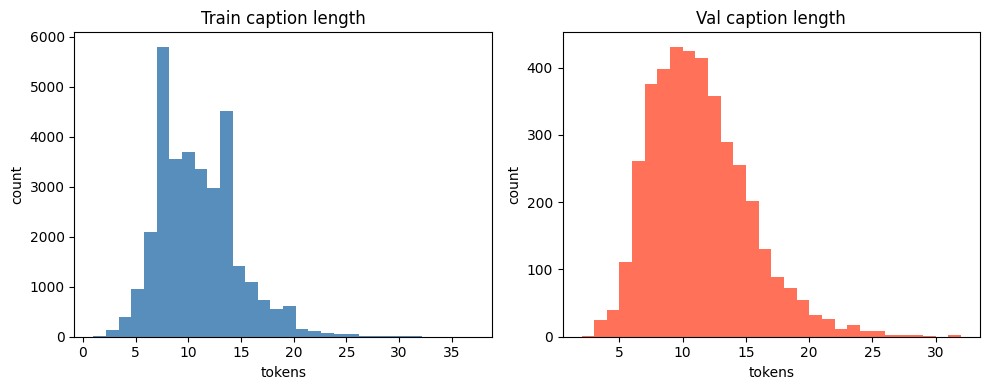

Top-15 train tokens: [('a', 50415), ('in', 15128), ('the', 14725), ('on', 8622), ('is', 7445), ('and', 7053), ('dog', 6623), ('with', 6143), ('man', 5815), ('of', 5368), ('two', 4504), ('white', 3141), ('black', 3134), ('boy', 2849), ('are', 2815)]


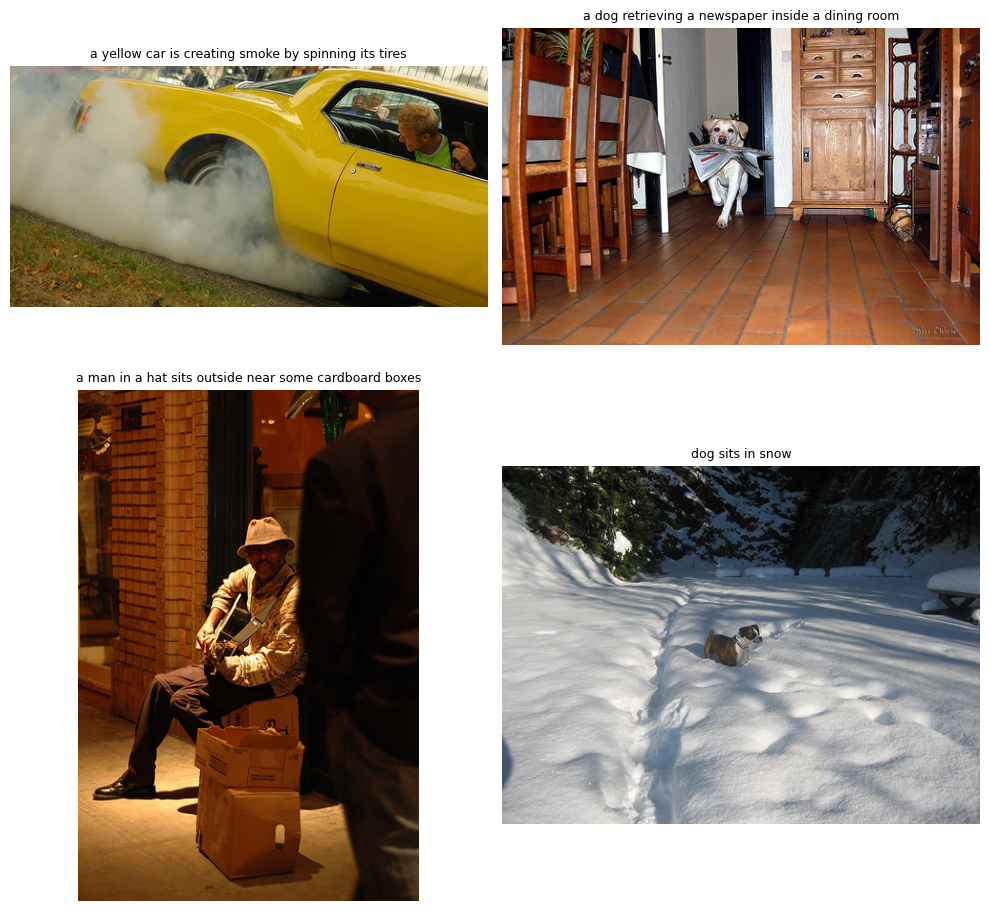

In [3]:
def clean_text(s):
    s = s.lower().strip()
    s = re.sub(r'[^a-z0-9\s]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s


clean_train_pairs = []
for p, img_id, cap in train_pairs:
    cap = clean_text(cap)
    if len(cap) > 0:
        clean_train_pairs.append((p, img_id, cap))

clean_val_pairs = []
for p, img_id, cap in val_pairs:
    cap = clean_text(cap)
    if len(cap) > 0:
        clean_val_pairs.append((p, img_id, cap))

train_pairs = clean_train_pairs
val_pairs = clean_val_pairs

if len(train_pairs) == 0 or len(val_pairs) == 0:
    raise ValueError('pairs kosong setelah cleaning caption')

print('After cleaning:', len(train_pairs), len(val_pairs))

train_img_unique = len({img_id for _, img_id, _ in train_pairs})
val_img_unique = len({img_id for _, img_id, _ in val_pairs})
train_lens = [len(word_tokenize(cap)) for _, _, cap in train_pairs]
val_lens = [len(word_tokenize(cap)) for _, _, cap in val_pairs]

print('Unique images -> train:', train_img_unique, '| val:', val_img_unique)
print('Caption length mean -> train: {:.2f} | val: {:.2f}'.format(np.mean(train_lens), np.mean(val_lens)))
print('Caption length p95  -> train: {:.0f} | val: {:.0f}'.format(np.percentile(train_lens, 95), np.percentile(val_lens, 95)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(train_lens, bins=30, color='steelblue', alpha=0.9)
axes[0].set_title('Train caption length')
axes[0].set_xlabel('tokens')
axes[0].set_ylabel('count')

axes[1].hist(val_lens, bins=30, color='tomato', alpha=0.9)
axes[1].set_title('Val caption length')
axes[1].set_xlabel('tokens')
axes[1].set_ylabel('count')
plt.tight_layout()
plt.show()

tok_counter = Counter()
for _, _, cap in train_pairs:
    tok_counter.update(word_tokenize(cap))

most_common = tok_counter.most_common(15)
print('Top-15 train tokens:', most_common)

sample_pairs = random.sample(train_pairs, k=min(4, len(train_pairs)))
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()
for ax, (img_path, _img_id, cap) in zip(axes, sample_pairs):
    img = Image.open(img_path).convert('RGB')
    ax.imshow(img)
    ax.axis('off')
    words = cap.split()
    preview = ' '.join(words[:16])
    if len(words) > 16:
        preview += ' ...'
    ax.set_title(preview, fontsize=9)
for j in range(len(sample_pairs), 4):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

# cleanup memory after EDA
for _v in [
    'clean_train_pairs', 'clean_val_pairs', 'train_lens', 'val_lens',
    'tok_counter', 'most_common', 'sample_pairs', 'img', 'words', 'preview'
]:
    if _v in globals():
        del globals()[_v]
del _v
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()
    torch.cuda.synchronize()


## Vocab Tokenizer


In [ ]:
def tokenizer(text):
    return word_tokenize(str(text).lower())


class Vocab:
    def __init__(self, stoi, default_index=0):
        self.stoi = stoi
        self.itos = [None] * len(stoi)
        for token, idx in stoi.items():
            self.itos[idx] = token
        self.default_index = default_index

    def __call__(self, tokens):
        return [self.stoi.get(t, self.default_index) for t in tokens]

    def __getitem__(self, token):
        return self.stoi[token]

    def __len__(self):
        return len(self.stoi)

    def get_itos(self):
        return self.itos

    def get_stoi(self):
        return self.stoi

    def set_default_index(self, idx):
        self.default_index = idx


counter = Counter()
for _, _, cap in train_pairs:
    counter.update(tokenizer(cap))

specials = [cfg.PAD_TOKEN, cfg.SOS_TOKEN, cfg.EOS_TOKEN, cfg.UNK_TOKEN]
stoi = {}
for sp in specials:
    if sp not in stoi:
        stoi[sp] = len(stoi)

for word, cnt in counter.items():
    if cnt >= cfg.MIN_FREQ and word not in stoi:
        stoi[word] = len(stoi)

vocab = Vocab(stoi)
vocab.set_default_index(vocab[cfg.UNK_TOKEN])
itos = vocab.get_itos()

pad_idx = vocab[cfg.PAD_TOKEN]
sos_idx = vocab[cfg.SOS_TOKEN]
eos_idx = vocab[cfg.EOS_TOKEN]
unk_idx = vocab[cfg.UNK_TOKEN]

print("Vocab size:", len(vocab))
print("Tokenizer backend: nltk-word_tokenize")

Vocab size: 4649
Tokenizer backend: nltk-word_tokenize


## Dataloader


In [ ]:
img_tfm = transforms.Compose(
    [
        transforms.Resize((cfg.IMG_SIZE, cfg.IMG_SIZE)),
        transforms.ToTensor(),
    ]
)

def make_cap_ids(cap):
    token_ids = [sos_idx] + vocab(tokenizer(cap)[: cfg.MAX_LEN - 2]) + [eos_idx]
    if len(token_ids) < cfg.MAX_LEN:
        token_ids += [pad_idx] * (cfg.MAX_LEN - len(token_ids))
    else:
        token_ids = token_ids[: cfg.MAX_LEN]
        token_ids[-1] = eos_idx
    return torch.tensor(token_ids, dtype=torch.long)


class PairDataset(Dataset):
    def __init__(self, pairs, tfm):
        self.pairs = pairs
        self.tfm = tfm

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, img_id, cap = self.pairs[idx]
        img = Image.open(img_path).convert('RGB')
        img = self.tfm(img)
        cap_ids = make_cap_ids(cap)
        return img, cap_ids, int(img_id), img_path


def collate_pairs(batch):
    images, caps, ids, paths = zip(*batch)
    images = torch.stack(images, dim=0)
    caps = torch.stack(caps, dim=0)
    ids = torch.tensor(ids, dtype=torch.long)
    return images, caps, ids, list(paths)


train_dataset = PairDataset(train_pairs, img_tfm)
val_dataset = PairDataset(val_pairs, img_tfm)

extract_train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.EXTRACT_BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_pairs,
)

extract_val_loader = DataLoader(
    val_dataset,
    batch_size=cfg.EXTRACT_BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_pairs,
)

val_ref_map = {}
for _, img_id, cap in val_pairs:
    val_ref_map.setdefault(int(img_id), []).append(cap)

val_img_id_to_path = {}
for img_path, img_id, _ in val_pairs:
    if int(img_id) not in val_img_id_to_path:
        val_img_id_to_path[int(img_id)] = img_path

print('Train pairs:', len(train_dataset), '| Val pairs:', len(val_dataset))
print('Extract train batches:', len(extract_train_loader), '| Extract val batches:', len(extract_val_loader))


Train pairs: 32360 | Val pairs: 4045
Extract train batches: 506 | Extract val batches: 64


## Global Feature Extractor


In [6]:
class GlobalFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()

        backbone = efficientnet_b3(weights=EfficientNet_B3_Weights.DEFAULT)
        self.features = backbone.features
        self.out_dim = 1536

        self.register_buffer(
            'mean',
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1),
        )
        self.register_buffer(
            'std',
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1),
        )

        for p in self.features.parameters():
            p.requires_grad = False

    def forward(self, x):
        x = (x - self.mean) / self.std
        fmap = self.features(x)
        g = F.adaptive_avg_pool2d(fmap, 1).flatten(1)
        return fmap, g


## Region Object Feature Extractor


In [7]:
class RegionFeatureExtractor(nn.Module):
    def __init__(self, topk=25):
        super().__init__()
        self.topk = topk
        self.region_dim = 1536

    def forward(self, fmap):
        b, c, h, w = fmap.shape
        regions = fmap.flatten(2).transpose(1, 2)
        scores = regions.mean(-1)

        k = min(self.topk, regions.size(1))
        idx = scores.topk(k, dim=1).indices
        idx = idx.unsqueeze(-1).expand(-1, -1, c)

        top_regions = torch.gather(regions, 1, idx)
        return top_regions


## Region Context Attention Fusion


In [8]:
class HABRefiner(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.cm = nn.Sequential(
            nn.Linear(dim, dim // 2),
            nn.ReLU(),
            nn.Linear(dim // 2, dim),
            nn.Sigmoid(),
        )
        self.sc = nn.Conv1d(dim, 1, kernel_size=3, padding=1)

    def forward(self, x):
        channel_weight = self.cm(x.mean(1)).unsqueeze(1)
        x = x * channel_weight

        spatial_weight = torch.sigmoid(self.sc(x.transpose(1, 2))).transpose(1, 2)
        x = x * spatial_weight

        return x


class RegionContextFusion(nn.Module):
    def __init__(self, region_dim, global_dim, d_model, num_heads, dropout):
        super().__init__()
        self.rp = nn.Linear(region_dim, d_model)
        self.gp = nn.Linear(global_dim, d_model)
        self.attn = nn.MultiheadAttention(
            d_model,
            num_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.norm = nn.LayerNorm(d_model)
        self.hab = HABRefiner(d_model)

    def forward(self, r, g):
        r = self.rp(r)
        g = self.gp(g).unsqueeze(1)
        kv = torch.cat([r, g], dim=1)

        out, _ = self.attn(query=r, key=kv, value=kv)
        fused = self.norm(r + out)

        return self.hab(fused)


## Decoder


In [9]:
class AdditiveAttention(nn.Module):
    def __init__(self, feat_dim, hidden_dim, attn_dim=256):
        super().__init__()
        self.fp = nn.Linear(feat_dim, attn_dim)
        self.hp = nn.Linear(hidden_dim, attn_dim)
        self.v = nn.Linear(attn_dim, 1)

    def forward(self, feats, h):
        e = self.v(torch.tanh(self.fp(feats) + self.hp(h).unsqueeze(1))).squeeze(-1)
        a = torch.softmax(e, dim=1)
        ctx = torch.sum(feats * a.unsqueeze(-1), dim=1)
        return ctx


class CaptionDecoderGRU(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, feat_dim, pad_idx, dropout):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.attn = AdditiveAttention(feat_dim, hidden_dim)
        self.gru = nn.GRUCell(embed_dim + feat_dim, hidden_dim)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.h = hidden_dim

    def forward(self, feats, caps):
        b, t = caps.size()
        h = torch.zeros(b, self.h, device=caps.device)
        emb = self.embed(caps)
        outs = []

        for i in range(t - 1):
            ctx = self.attn(feats, h)
            inp = torch.cat([emb[:, i, :], ctx], dim=-1)
            h = self.gru(inp, h)
            outs.append(self.fc(self.drop(h)).unsqueeze(1))

        return torch.cat(outs, dim=1)

    @torch.no_grad()
    def generate(self, feats, sos_idx, max_len, eos_idx=None):
        b = feats.size(0)
        h = torch.zeros(b, self.h, device=feats.device)
        tok = torch.full((b,), sos_idx, dtype=torch.long, device=feats.device)
        seq = []

        for _ in range(max_len):
            ctx = self.attn(feats, h)
            inp = torch.cat([self.embed(tok), ctx], dim=-1)
            h = self.gru(inp, h)
            tok = self.fc(h).argmax(-1)
            seq.append(tok.unsqueeze(1))

            if eos_idx is not None and (tok == eos_idx).all():
                break

        return torch.cat(seq, dim=1)


## Full Model


In [ ]:
class FrozenFeatureEncoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.g = GlobalFeatureExtractor()
        self.r = RegionFeatureExtractor(cfg.TOPK_REGIONS)
        self.f = RegionContextFusion(
            self.r.region_dim,
            self.g.out_dim,
            cfg.FUSION_DIM,
            cfg.NUM_HEADS,
            cfg.DROPOUT,
        )

        for p in self.parameters():
            p.requires_grad = False

    def forward(self, images):
        fmap, g = self.g(images)
        r = self.r(fmap)
        return self.f(r, g)


@torch.no_grad()
def extract_feature_bank(loader, encoder, desc):
    feat_list = []
    cap_list = []
    id_list = []

    encoder.eval()
    for i, (images, caps, img_ids, _paths) in enumerate(tqdm(loader, desc=desc, leave=False), start=1):
        images = images.to(device, non_blocking=True)

        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            feats = encoder(images)

        feat_list.append(feats.detach().cpu())
        cap_list.append(caps)
        id_list.append(img_ids)

        del feats, images, caps, img_ids, _paths
        if device.type == 'cuda' and (i % cfg.EMPTY_CACHE_EVERY == 0):
            torch.cuda.empty_cache()

    feat_bank = torch.cat(feat_list, dim=0)
    cap_bank = torch.cat(cap_list, dim=0)
    id_bank = torch.cat(id_list, dim=0)

    del feat_list, cap_list, id_list
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.synchronize()

    return feat_bank, cap_bank, id_bank


feature_encoder = FrozenFeatureEncoder(cfg).to(device)
train_feats, train_caps, train_ids = extract_feature_bank(extract_train_loader, feature_encoder, 'Extract train feats')
val_feats, val_caps, val_ids = extract_feature_bank(extract_val_loader, feature_encoder, 'Extract val feats')

train_feat_dataset = torch.utils.data.TensorDataset(train_feats, train_caps, train_ids)
val_feat_dataset = torch.utils.data.TensorDataset(val_feats, val_caps, val_ids)

train_loader = DataLoader(
    train_feat_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=True,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=True,
)

val_loader = DataLoader(
    val_feat_dataset,
    batch_size=max(1, cfg.BATCH_SIZE // 2),
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=True,
)

val_id_to_feat = {}
for feat, img_id in zip(val_feats, val_ids.tolist()):
    if int(img_id) not in val_id_to_feat:
        val_id_to_feat[int(img_id)] = feat

model = CaptionDecoderGRU(
    len(vocab),
    cfg.EMBED_DIM,
    cfg.HIDDEN_DIM,
    cfg.FUSION_DIM,
    pad_idx,
    cfg.DROPOUT,
).to(device)

if torch.cuda.device_count() > 1 and device.type == 'cuda':
    model = nn.DataParallel(model)

criterion = nn.CrossEntropyLoss(ignore_index=pad_idx, label_smoothing=cfg.LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=cfg.LR,
    weight_decay=cfg.WEIGHT_DECAY,
    betas=(cfg.ADAM_BETA1, cfg.ADAM_BETA2),
    eps=cfg.ADAM_EPS,
)

warmup_epochs = max(1, min(cfg.WARMUP_EPOCHS, cfg.EPOCHS))
cosine_epochs = max(1, cfg.EPOCHS - warmup_epochs)
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[
        torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.2, end_factor=1.0, total_iters=warmup_epochs),
        torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cosine_epochs, eta_min=cfg.MIN_LR),
    ],
    milestones=[warmup_epochs],
)

base_model = model.module if isinstance(model, nn.DataParallel) else model
ema_model = copy.deepcopy(base_model).to(device)
for p in ema_model.parameters():
    p.requires_grad = False

scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

# cleanup raw image loaders and frozen encoder after feature extraction
for _v in ['feature_encoder', 'extract_train_loader', 'extract_val_loader', 'train_dataset', 'val_dataset']:
    if _v in globals():
        del globals()[_v]
del _v
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

print('Feature banks:', train_feats.shape, val_feats.shape)
print('Train batches:', len(train_loader), '| Val batches:', len(val_loader))
print('Optimizer: AdamW | Scheduler: Warmup + Cosine | Label smoothing:', cfg.LABEL_SMOOTHING)
print('EMA enabled:', cfg.USE_EMA, '| EMA decay:', cfg.EMA_DECAY)
print('Model ready (decoder-only training)')

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 204MB/s]


Feature banks: torch.Size([32360, 25, 512]) torch.Size([4045, 25, 512])
Train batches: 253 | Val batches: 64
Optimizer: AdamW | Scheduler: Warmup + Cosine | Label smoothing: 0.1
EMA enabled: True | EMA decay: 0.999
Model ready (decoder-only training)


## Training


In [ ]:
import time

def update_ema(ema_module, src_module, decay):
    with torch.no_grad():
        ema_state = ema_module.state_dict()
        src_state = src_module.state_dict()
        for k, v in ema_state.items():
            src_v = src_state[k].detach()
            if v.dtype.is_floating_point:
                v.mul_(decay).add_(src_v, alpha=1.0 - decay)
            else:
                v.copy_(src_v)


best_val = 1e18
history = {
    'train_loss': [],
    'val_loss': [],
    'lr': [],
    'epoch_sec': [],
}

for epoch in range(cfg.EPOCHS):
    t0 = time.time()

    model.train()
    train_loss_sum = 0.0
    train_bar = tqdm(train_loader, desc=f'Train E{epoch+1}/{cfg.EPOCHS}', leave=False)
    for step, (feats, caps, _ids) in enumerate(train_bar, start=1):
        feats = feats.to(device, non_blocking=True)
        caps = caps.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits = model(feats, caps)
            target = caps[:, 1:]
            loss = criterion(
                logits.reshape(-1, logits.size(-1)),
                target.reshape(-1),
            )

        scaler.scale(loss).backward()
        if cfg.CLIP_GRAD_NORM > 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.CLIP_GRAD_NORM)

        scaler.step(optimizer)
        scaler.update()

        if cfg.USE_EMA:
            src = model.module if isinstance(model, nn.DataParallel) else model
            update_ema(ema_model, src, cfg.EMA_DECAY)

        batch_loss = loss.detach().item()
        train_loss_sum += batch_loss
        if step % 20 == 0 or step == len(train_loader):
            train_bar.set_postfix({'batch_loss': f'{batch_loss:.4f}', 'avg_loss': f'{(train_loss_sum/step):.4f}'})

        del logits, target, loss, feats, caps, _ids
        if device.type == 'cuda' and (step % cfg.EMPTY_CACHE_EVERY == 0):
            torch.cuda.empty_cache()

    tr = train_loss_sum / max(1, len(train_loader))

    if device.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.synchronize()

    eval_runner = ema_model if cfg.USE_EMA else (model.module if isinstance(model, nn.DataParallel) else model)
    eval_runner.eval()

    val_loss_sum = 0.0
    val_bar = tqdm(val_loader, desc=f'Val   E{epoch+1}/{cfg.EPOCHS}', leave=False)
    with torch.no_grad():
        for i, (feats, caps, _ids) in enumerate(val_bar, start=1):
            feats = feats.to(device, non_blocking=True)
            caps = caps.to(device, non_blocking=True)

            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = eval_runner(feats, caps)
                target = caps[:, 1:]
                loss = criterion(
                    logits.reshape(-1, logits.size(-1)),
                    target.reshape(-1),
                )

            batch_val_loss = loss.detach().item()
            val_loss_sum += batch_val_loss
            if i % 20 == 0 or i == len(val_loader):
                val_bar.set_postfix({'batch_loss': f'{batch_val_loss:.4f}', 'avg_loss': f'{(val_loss_sum/i):.4f}'})

            del logits, target, loss, feats, caps, _ids
            if device.type == 'cuda' and (i % 20 == 0):
                torch.cuda.empty_cache()

    va = val_loss_sum / max(1, len(val_loader))

    scheduler.step()

    epoch_sec = time.time() - t0
    lr_now = optimizer.param_groups[0]['lr']

    history['train_loss'].append(tr)
    history['val_loss'].append(va)
    history['lr'].append(lr_now)
    history['epoch_sec'].append(epoch_sec)

    improved = va < best_val
    if improved:
        best_val = va
        if cfg.USE_EMA:
            state_dict = ema_model.state_dict()
        else:
            state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
        torch.save(
            {'model': state_dict, 'cfg': cfg.__dict__, 'vocab_stoi': vocab.get_stoi()},
            CKPT_PATH,
        )

    print('Epoch {}/{} | train_loss={:.4f} | val_loss={:.4f} | lr={:.2e} | time={:.1f}s{}'.format(
        epoch + 1, cfg.EPOCHS, tr, va, lr_now, epoch_sec, ' | best' if improved else ''
    ))

print('Saved checkpoint:', CKPT_PATH)


Epoch 1/10 | train_loss=6.1802 | val_loss=8.2327 | lr=1.80e-04 | time=28.5s | best


Epoch 2/10 | train_loss=4.8385 | val_loss=7.7371 | lr=3.00e-04 | time=27.1s | best


Epoch 3/10 | train_loss=4.3507 | val_loss=6.9649 | lr=2.89e-04 | time=26.8s | best


Epoch 4/10 | train_loss=4.0590 | val_loss=5.9126 | lr=2.56e-04 | time=26.9s | best


Epoch 5/10 | train_loss=3.8867 | val_loss=5.0256 | lr=2.08e-04 | time=27.0s | best


Epoch 6/10 | train_loss=3.7703 | val_loss=4.5240 | lr=1.50e-04 | time=27.2s | best


Epoch 7/10 | train_loss=3.6890 | val_loss=4.2479 | lr=9.33e-05 | time=27.2s | best


Epoch 8/10 | train_loss=3.6352 | val_loss=4.0836 | lr=4.48e-05 | time=27.1s | best


Epoch 9/10 | train_loss=3.6007 | val_loss=3.9807 | lr=1.24e-05 | time=27.0s | best


Epoch 10/10 | train_loss=3.5844 | val_loss=3.9150 | lr=1.00e-06 | time=27.5s | best
Saved checkpoint: /kaggle/working/effb3_gru_flickr8k_output/best_model.pt


## Training Curves


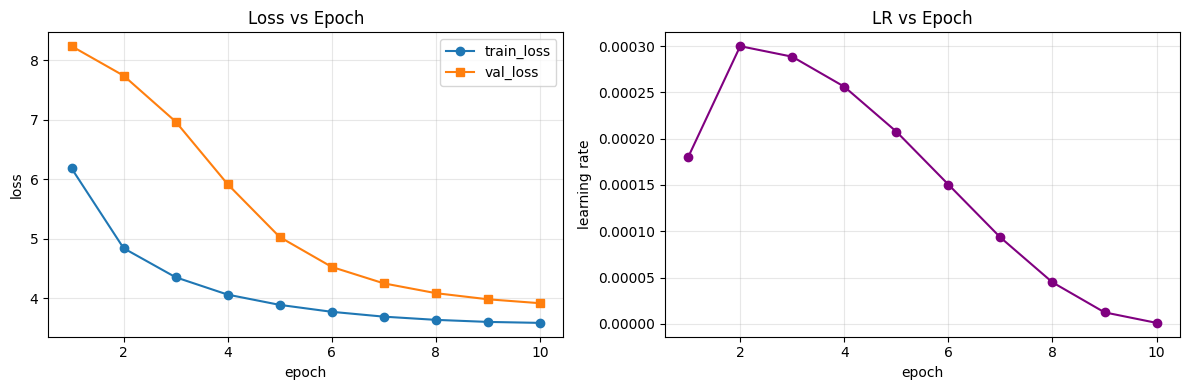

Best val loss: 3.9149525836110115


In [12]:
if 'history' not in globals() or len(history.get('train_loss', [])) == 0:
    raise ValueError('history kosong. Jalankan cell training dulu.')

epochs = list(range(1, len(history['train_loss']) + 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history['train_loss'], marker='o', label='train_loss')
axes[0].plot(epochs, history['val_loss'], marker='s', label='val_loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].set_title('Loss vs Epoch')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history['lr'], marker='o', color='purple')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('learning rate')
axes[1].set_title('LR vs Epoch')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print('Best val loss:', min(history['val_loss']))


## Evaluation


In [13]:
model.eval()
runner = ema_model if ('ema_model' in globals() and cfg.USE_EMA) else (model.module if isinstance(model, nn.DataParallel) else model)

refs = []
hyps = []
smooth = SmoothingFunction().method1
seen = set()

with torch.no_grad():
    for feats, _caps, img_ids in tqdm(val_loader, desc='Eval', leave=False):
        feats = feats.to(device, non_blocking=True)
        preds = runner.generate(feats, sos_idx, cfg.MAX_LEN, eos_idx=eos_idx).cpu().numpy()

        for img_id, pr in zip(img_ids.tolist(), preds):
            if img_id in seen:
                continue
            seen.add(img_id)

            words = []
            for token_id in pr:
                tok = itos[int(token_id)] if int(token_id) < len(itos) else cfg.UNK_TOKEN
                if tok == cfg.EOS_TOKEN:
                    break
                if tok not in {cfg.SOS_TOKEN, cfg.PAD_TOKEN}:
                    words.append(tok)

            gt_refs = []
            for ref_caption in val_ref_map.get(img_id, []):
                ref_tokens = tokenizer(ref_caption)
                if len(ref_tokens) > 0:
                    gt_refs.append(ref_tokens)

            if gt_refs and words:
                refs.append(gt_refs)
                hyps.append(words)

if len(hyps) == 0:
    metrics = {'BLEU-1': 0.0, 'BLEU-4': 0.0}
else:
    metrics = {
        'BLEU-1': corpus_bleu(refs, hyps, weights=(1, 0, 0, 0), smoothing_function=smooth),
        'BLEU-4': corpus_bleu(refs, hyps, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth),
    }

(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print(metrics)


{'BLEU-1': 0.5032324268855823, 'BLEU-4': 0.13231754165912527}


## Inference


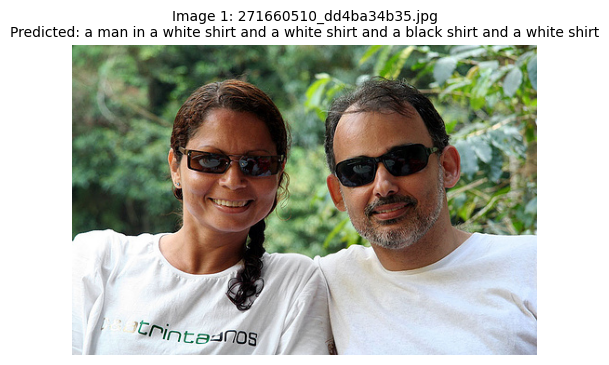

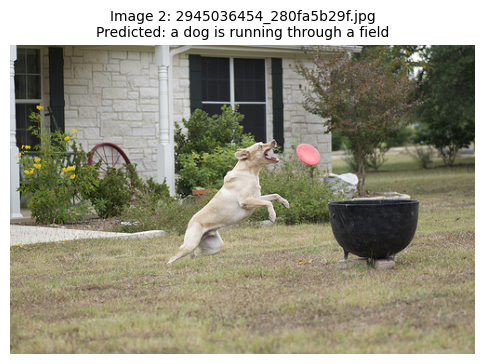

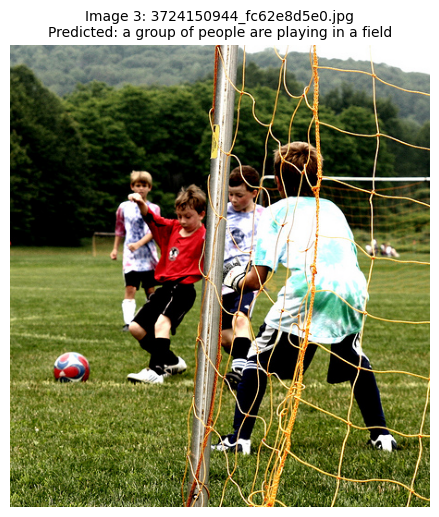

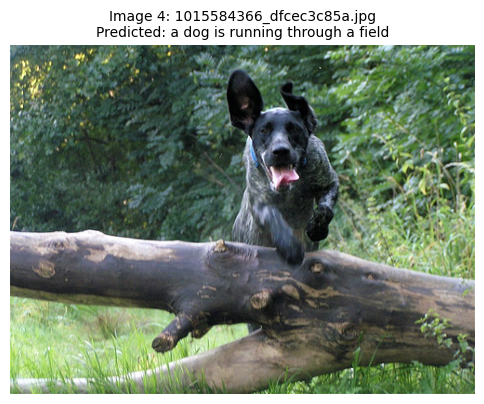

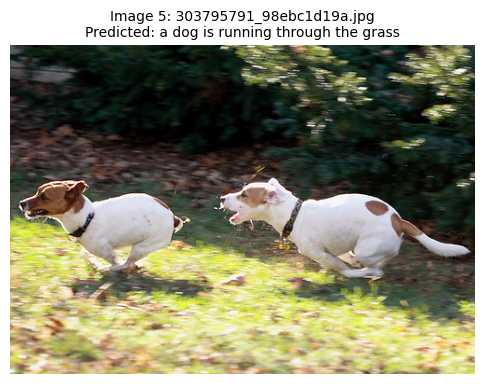

Done inference for 5 images


In [ ]:
runner = ema_model if ('ema_model' in globals() and cfg.USE_EMA) else (model.module if isinstance(model, nn.DataParallel) else model)

sample_ids = list(val_id_to_feat.keys())
random.shuffle(sample_ids)
sample_ids = sample_ids[:5]

for i, img_id in enumerate(sample_ids, start=1):
    img_path = val_img_id_to_path[int(img_id)]
    img = Image.open(img_path).convert('RGB')

    feat = val_id_to_feat[int(img_id)].unsqueeze(0).to(device)
    with torch.no_grad():
        pred = runner.generate(feat, sos_idx, cfg.MAX_LEN, eos_idx=eos_idx)[0].cpu().numpy()

    pred_words = []
    for token_id in pred:
        tok = itos[int(token_id)] if int(token_id) < len(itos) else cfg.UNK_TOKEN
        if tok == cfg.EOS_TOKEN:
            break
        if tok not in {cfg.SOS_TOKEN, cfg.PAD_TOKEN}:
            pred_words.append(tok)

    pred_caption = ' '.join(pred_words) if len(pred_words) else '<empty>'

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f'Image {i}: {Path(img_path).name}\nPredicted: {pred_caption}', fontsize=10)
    plt.show()

print('Done inference for', len(sample_ids), 'images')